# 02 · Análisis exploratorio (EDA)

**Objetivo:** entender el comportamiento del Brent y de sus variables explicativas sobre el dataset limpio del notebook 01, y extraer conclusiones que guíen el feature engineering y el modelado.

Preguntas:
1. ¿Cómo se ha movido el Brent en 2000-2026 y qué eventos explican sus picos y caídas? *(base de la sección "ciclo económico" de la app)*
2. ¿Qué propiedades estadísticas tienen el precio y sus retornos?
3. ¿Hay estacionalidad?
4. ¿Qué relación tienen las variables externas con el Brent? ¿Es estable en el tiempo?
5. ¿Cuánta incertidumbre hay a 5, 63 y 252 días y cuánto se equivoca el modelo ingenuo?

In [1]:
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller, kpss

from oil_forecast.config import HORIZONS, TARGET
from oil_forecast.data import load_dataset
from oil_forecast.events import EVENTS
from oil_forecast.plotting import set_style

set_style()
pd.set_option("display.float_format", "{:.3f}".format)

df = load_dataset()
price = df[TARGET]
ret = np.log(price).diff().dropna()
print(f"{len(df):,} días de cotización del Brent · {df.index.min():%d/%m/%Y} - {df.index.max():%d/%m/%Y}")

6,501 días de cotización del Brent · 04/01/2000 - 03/11/2026


## 1. El Brent en 2000-2026 y el ciclo económico

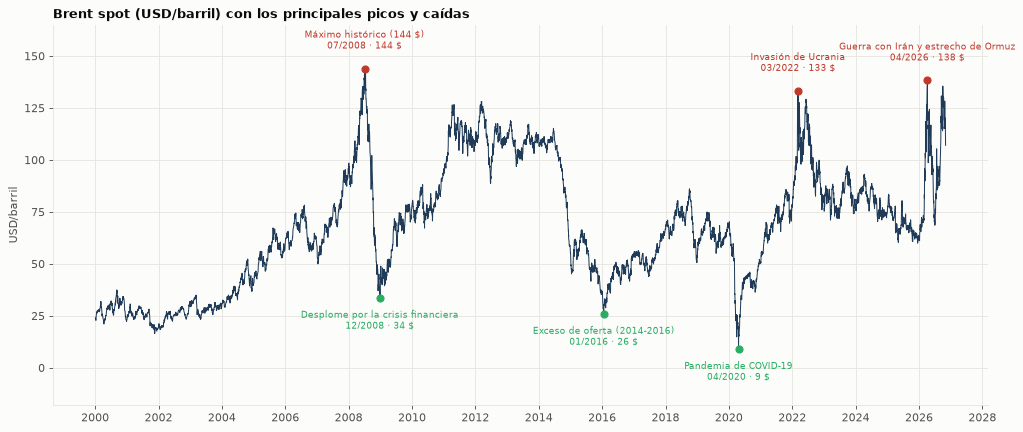

In [2]:
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(df.index, price, color="#1f3b57", lw=0.9)
for ev in EVENTS:
    d = pd.Timestamp(ev["date"])
    p = price.asof(d)
    color = "#c0392b" if ev["kind"] == "pico" else "#27ae60"
    ax.scatter(d, p, color=color, s=40, zorder=3)
    ax.annotate(f"{ev['title']}\n{d:%m/%Y} · {p:.0f} $", (d, p), xytext=(0, 18 if ev["kind"] == "pico" else -28),
                textcoords="offset points", ha="center", fontsize=8, color=color)
ax.set_title("Brent spot (USD/barril) con los principales picos y caídas")
ax.set_ylabel("USD/barril"); ax.set_ylim(-18, 165)
ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()

In [3]:
yearly = price.resample("YE").agg(["min", "mean", "max", "last"])
yearly["var. anual %"] = yearly["last"].pct_change() * 100
yearly["volatilidad %"] = ret.groupby(ret.index.year).std().values * np.sqrt(252) * 100
yearly.index = yearly.index.year
yearly.round(1).T

Date,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
min,21.000,16.500,18.300,23.200,29.000,40.800,55.800,50.000,33.700,39.400,...,44.000,50.600,53.200,9.100,50.400,76.000,71.000,70.300,59.900,61.100
mean,28.800,24.500,25.100,29.000,38.800,54.900,65.200,72.600,96.900,61.700,...,54.100,71.300,64.300,42.000,70.900,100.900,82.500,80.500,69.100,96.500
max,37.400,30.700,32.000,34.900,52.300,67.300,78.300,95.900,144.000,78.700,...,66.800,86.100,74.900,70.200,85.800,133.200,97.100,93.100,83.500,138.200
last,22.300,19.400,32.000,30.300,40.400,58.300,59.000,93.700,35.800,77.900,...,66.700,50.600,67.800,51.200,77.200,82.800,77.700,74.600,61.400,107.000
var. anual %,NaN,-13.200,65.500,-5.400,33.300,44.500,1.100,58.900,-61.800,117.500,...,21.400,-24.200,34.000,-24.400,50.800,7.200,-6.200,-4.000,-17.700,74.500
volatilidad %,53.700,54.100,36.500,39.600,38.700,33.700,31.600,27.900,49.600,51.400,...,25.900,29.500,33.100,114.300,33.900,47.300,34.000,26.600,30.600,70.200


| Periodo | Movimiento | Causa principal | Tipo de shock |
|---|---|---|---|
| 2003-2008 | 25 $ → 144 $ | Superciclo de materias primas (China), oferta ajustada | Demanda |
| 2008 | 144 $ → 34 $ | Crisis financiera global | Demanda |
| 2011-2014 | ≈110 $ estable | Primavera Árabe (Libia), demanda emergente | Oferta + demanda |
| 2014-2016 | 115 $ → 26 $ | Esquisto de EE. UU. + OPEP sin recortes | **Oferta** |
| 2020 | 70 $ → 9 $ | Pandemia: confinamientos | Demanda |
| 2022 | 78 $ → 133 $ | Invasión de Ucrania, sanciones a Rusia | **Oferta** |
| 2026 | 71 $ → 138 $ | Guerra con Irán, bloqueo de Ormuz | **Oferta** |

Los grandes movimientos se deben a shocks externos imposibles de anticipar con la propia serie (una pandemia, una guerra). Esto marca el techo de lo que cualquier modelo de series temporales puede lograr y debe decirse con claridad en la app.

## 2. Brent frente a WTI y a los futuros

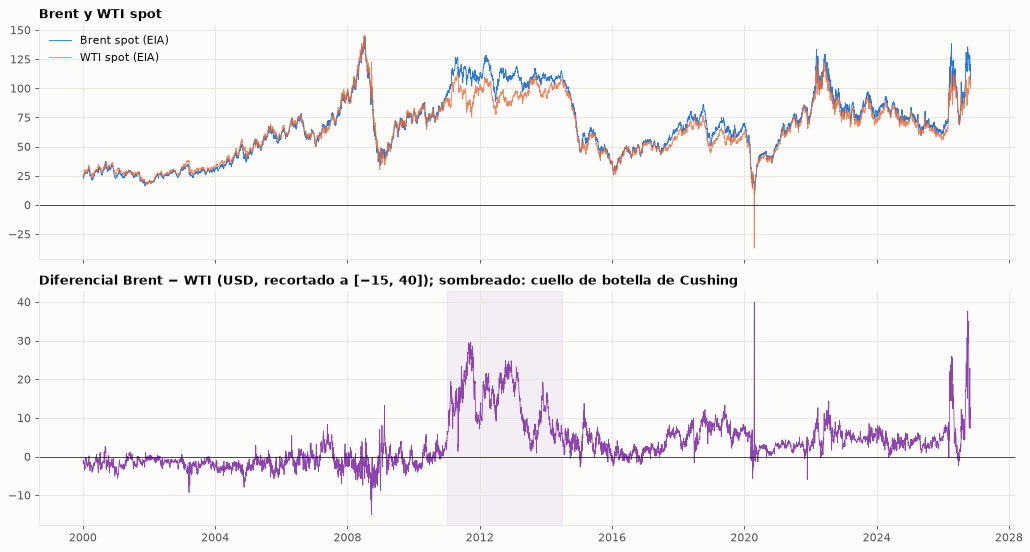

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(df.index, price, label="Brent spot (EIA)", lw=0.8)
axes[0].plot(df.index, df["wti"], label="WTI spot (EIA)", lw=0.8, alpha=0.8)
axes[0].axhline(0, color="k", lw=0.6); axes[0].legend(); axes[0].set_title("Brent y WTI spot")
spread = price - df["wti"]
axes[1].plot(df.index, spread.clip(-15, 40), color="#8e44ad", lw=0.7); axes[1].axhline(0, color="k", lw=0.6)
axes[1].axvspan(pd.Timestamp("2011-01-01"), pd.Timestamp("2014-06-30"), color="#8e44ad", alpha=0.08)
axes[1].set_title("Diferencial Brent − WTI (USD, recortado a [−15, 40]); sombreado: cuello de botella de Cushing")
plt.tight_layout()

mean    5.713
min    -4.610
max    33.260
dtype: float64

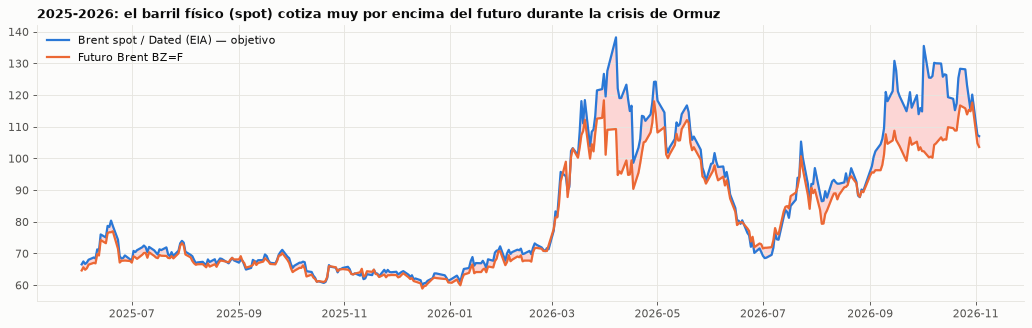

In [5]:
recent = df.loc["2025-06":, [TARGET, "brent_fut_Close"]].dropna()
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(recent.index, recent[TARGET], label="Brent spot / Dated (EIA) — objetivo")
ax.plot(recent.index, recent["brent_fut_Close"], label="Futuro Brent BZ=F")
ax.fill_between(recent.index, recent[TARGET], recent["brent_fut_Close"], alpha=0.15, color="red")
ax.set_title("2025-2026: el barril físico (spot) cotiza muy por encima del futuro durante la crisis de Ormuz"); ax.legend()
plt.tight_layout()
(recent[TARGET] - recent["brent_fut_Close"]).loc["2026"].describe()[["mean", "min", "max"]]

- Brent y WTI se mueven casi juntos; el diferencial se amplió en 2011-2014 (exceso de crudo en Cushing, EE. UU.) y es una variable con información propia.
- En 2026 el spot llegó a superar al futuro en más de 30 $: la prima por el barril disponible *ya*. El objetivo es el spot, así que los futuros ayudan pero no lo sustituyen.

## 3. Propiedades estadísticas

In [6]:
def stationarity(s, name):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        adf_p = adfuller(s.dropna(), autolag="AIC")[1]
        kpss_p = kpss(s.dropna(), regression="c", nlags="auto")[1]
    return {"serie": name, "ADF p-valor": adf_p, "KPSS p-valor": kpss_p,
            "¿estacionaria?": "sí" if (adf_p < 0.05 and kpss_p > 0.05) else "no"}

pd.DataFrame([stationarity(price, "precio"), stationarity(np.log(price), "log(precio)"),
              stationarity(ret, "retorno log diario")]).set_index("serie")

,ADF p-valor,KPSS p-valor,¿estacionaria?
serie,,,
precio,0.054,0.010,no
log(precio),0.056,0.010,no
retorno log diario,0.000,0.100,sí


volatilidad anualizada (%)    43.530
asimetría                     -1.730
curtosis (exceso)             63.750
peor día (%)                 -64.370
mejor día (%)                 41.200
días con |retorno| > 5 %     319.000


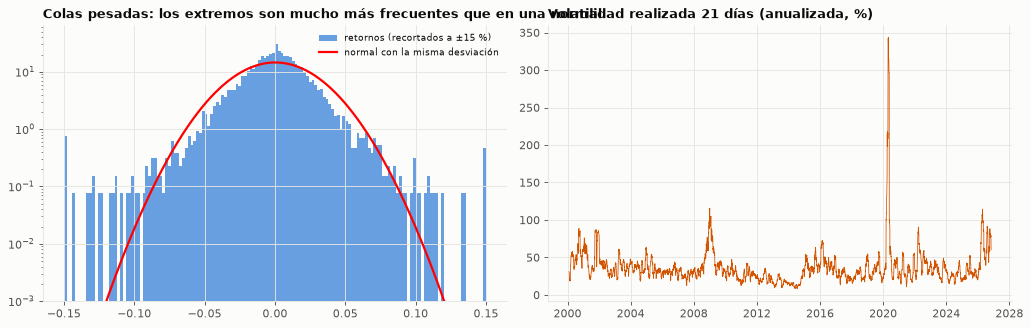

In [7]:
desc = pd.Series({
    "volatilidad anualizada (%)": ret.std() * np.sqrt(252) * 100,
    "asimetría": stats.skew(ret),
    "curtosis (exceso)": stats.kurtosis(ret),
    "peor día (%)": ret.min() * 100,
    "mejor día (%)": ret.max() * 100,
    "días con |retorno| > 5 %": (ret.abs() > 0.05).sum(),
})
print(desc.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.linspace(-0.15, 0.15, 400)
axes[0].hist(ret.clip(-0.15, 0.15), bins=150, density=True, alpha=0.7, label="retornos (recortados a ±15 %)")
axes[0].plot(x, stats.norm.pdf(x, ret.mean(), ret.std()), "r", label="normal con la misma desviación")
axes[0].set_yscale("log"); axes[0].set_ylim(1e-3, None); axes[0].legend(fontsize=8)
axes[0].set_title("Colas pesadas: los extremos son mucho más frecuentes que en una normal")
vol = ret.rolling(21).std() * np.sqrt(252) * 100
axes[1].plot(vol.index, vol, lw=0.7, color="#d35400"); axes[1].set_title("Volatilidad realizada 21 días (anualizada, %)")
plt.tight_layout()

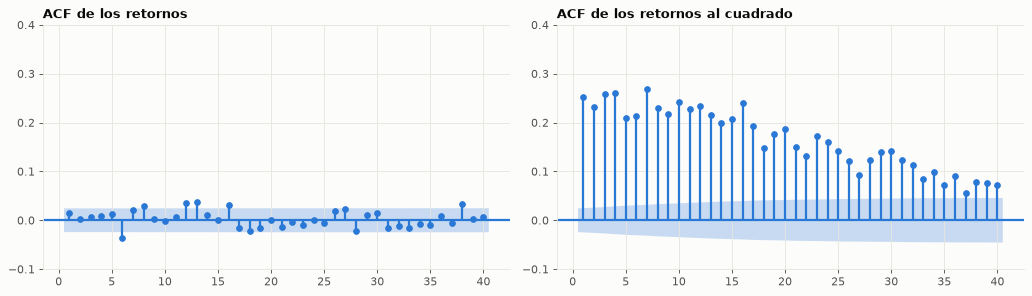

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
plot_acf(ret.clip(-0.15, 0.15), lags=40, ax=axes[0], zero=False, title="ACF de los retornos")
plot_acf(ret.clip(-0.15, 0.15) ** 2, lags=40, ax=axes[1], zero=False, title="ACF de los retornos al cuadrado")
for a in axes: a.set_ylim(-0.1, 0.4)
plt.tight_layout()

- El **precio no es estacionario**; el **retorno sí** → se modelarán retornos acumulados y se reconstruirá el precio.
- Los retornos **casi no tienen autocorrelación** (paseo aleatorio): el ingenuo será muy difícil de batir, sobre todo a 5 días.
- Los retornos al cuadrado **sí están autocorrelacionados**: la **volatilidad es predecible** (agrupamiento de volatilidad). Es la clave para construir intervalos de incertidumbre que se ensanchen en las crisis.
- Colas muy pesadas (curtosis enorme por 2020) → las entradas se winsorizarán.

## 4. ¿Hay estacionalidad?

Kruskal-Wallis por mes: p-valor = 0.069
Kruskal-Wallis por día de la semana: p-valor = 0.069


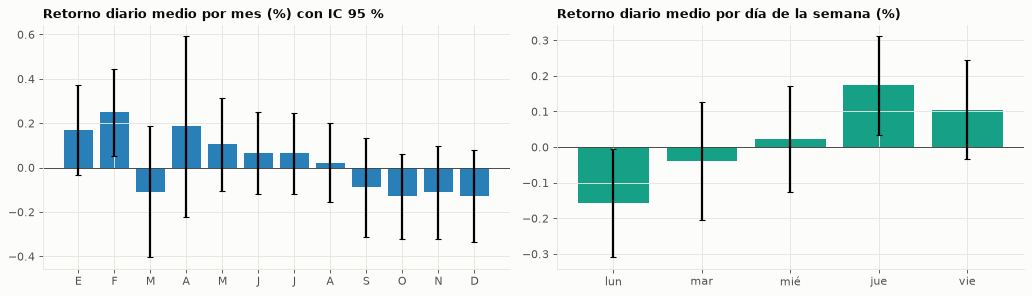

In [9]:
by_month = ret.groupby(ret.index.month).agg(["mean", "sem"]) * 100
by_dow = ret.groupby(ret.index.day_of_week).agg(["mean", "sem"]) * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(by_month.index, by_month["mean"], yerr=1.96 * by_month["sem"], color="#2980b9", capsize=3)
axes[0].set_xticks(range(1, 13), ["E", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
axes[0].set_title("Retorno diario medio por mes (%) con IC 95 %")
axes[1].bar(by_dow.index, by_dow["mean"], yerr=1.96 * by_dow["sem"], color="#16a085", capsize=3)
axes[1].set_xticks(range(5), ["lun", "mar", "mié", "jue", "vie"]); axes[1].set_title("Retorno diario medio por día de la semana (%)")
for a in axes: a.axhline(0, color="k", lw=0.6)
plt.tight_layout()
for name, groups in [("mes", ret.index.month), ("día de la semana", ret.index.day_of_week)]:
    p = stats.kruskal(*[g.values for _, g in ret.groupby(groups)]).pvalue
    print(f"Kruskal-Wallis por {name}: p-valor = {p:.3f}")

Ninguna diferencia es significativa al 5 % (y con 12 meses y 5 días comparados, alguna barra "llamativa" es esperable por azar). **No se crearán variables de calendario**: añadirían ruido que la red podría sobreajustar.

## 5. Relación con las variables externas

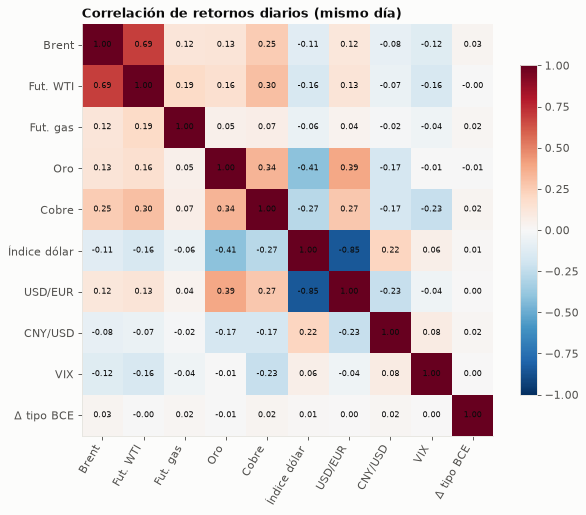

In [10]:
def log_ret(s):
    return np.log(s.where(s > 0)).diff()

names = {TARGET: "Brent", "wti_fut_Close": "Fut. WTI", "gas_fut": "Fut. gas", "oro": "Oro", "cobre": "Cobre",
         "indice_dolar": "Índice dólar", "usd_por_eur": "USD/EUR", "cny_por_usd": "CNY/USD", "vix": "VIX"}
rets = pd.DataFrame({n: log_ret(df[c]) for c, n in names.items()})
rets = rets.clip(rets.quantile(0.005), rets.quantile(0.995), axis=1)
rets["Δ tipo BCE"] = df["tipo_bce"].diff()
corr = rets.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right"); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False); fig.colorbar(im, shrink=0.8); ax.set_title("Correlación de retornos diarios (mismo día)")
plt.tight_layout()

In [11]:
lead = pd.DataFrame({f"retardo {k}": [rets["Brent"].corr(rets[c].shift(k)) for c in rets.columns] for k in range(1, 6)},
                    index=rets.columns)
print("Correlación entre el retorno del Brent hoy y el de cada variable k días antes:")
lead.round(3)

Correlación entre el retorno del Brent hoy y el de cada variable k días antes:


,retardo 1,retardo 2,retardo 3,retardo 4,retardo 5
Brent,0.016,0.002,0.010,0.012,0.006
Fut. WTI,0.183,0.021,0.003,0.018,-0.001
Fut. gas,0.059,0.003,0.003,-0.008,0.002
Oro,0.023,0.009,-0.012,0.002,-0.012
Cobre,0.052,-0.006,0.019,0.011,0.009
Índice dólar,-0.013,0.014,0.001,-0.029,0.007
USD/EUR,-0.016,-0.002,0.001,0.022,-0.004
CNY/USD,-0.013,0.004,0.002,-0.006,0.020
VIX,-0.059,-0.025,-0.021,0.019,0.009
Δ tipo BCE,-0.034,0.026,-0.013,0.009,0.007


,Índice dólar,Cobre,VIX,Oro
Date,,,,
2019-12-31,0.070,0.220,-0.220,-0.130
2020-12-31,-0.040,0.340,-0.380,0.070
2021-12-31,-0.160,0.320,-0.330,0.010
2022-12-31,-0.200,0.420,-0.030,0.350
2023-12-31,-0.130,0.250,-0.030,0.020
2024-12-31,0.100,0.130,-0.020,0.220
2025-12-31,0.180,0.150,-0.160,0.110
2026-12-31,0.190,-0.200,0.310,-0.160


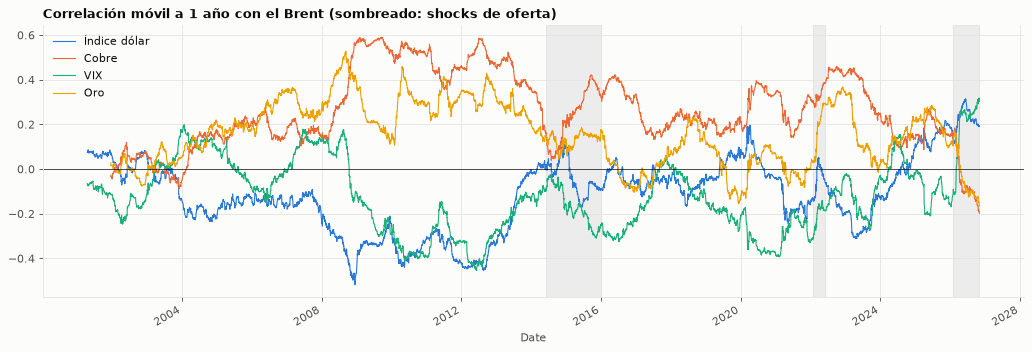

In [12]:
rolling = pd.DataFrame({n: rets["Brent"].rolling(252).corr(rets[n]) for n in ["Índice dólar", "Cobre", "VIX", "Oro"]})
fig, ax = plt.subplots(figsize=(13, 4.5))
rolling.plot(ax=ax, lw=1)
ax.axhline(0, color="k", lw=0.6)
for start, end in [("2014-06", "2016-01"), ("2022-02", "2022-06"), ("2026-02", "2026-11")]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="grey", alpha=0.12)
ax.set_title("Correlación móvil a 1 año con el Brent (sombreado: shocks de oferta)")
plt.tight_layout()
rolling.resample("YE").last().loc["2019":].round(2)

**Conclusiones:**
- El mismo día, el Brent se mueve con el futuro del WTI (ρ ≈ 0,7) y, en menor medida, con el cobre (actividad industrial), el VIX (aversión al riesgo, signo negativo) y el dólar (signo negativo: un dólar fuerte abarata el crudo).
- Con retardo casi todo desaparece, **salvo el retardo 1 del futuro WTI (ρ ≈ 0,18)**: el desfase horario entre el cierre de Londres y el de Nueva York hace que lo que pasa en EE. UU. por la tarde se refleje en el Brent del día siguiente.
- **Las relaciones no son estables.** Con shocks de demanda (2008-2012, 2020) el petróleo sube con el cobre y baja con el VIX y el dólar. Con el **shock de oferta de 2026 se invierten**: el crudo sube *a la vez* que el miedo (VIX) y el dólar, y en contra del cobre (la subida del petróleo amenaza el crecimiento). Un modelo entrenado sobre el histórico aprende sobre todo el régimen "de demanda", y ese es un **factor que puede invalidar la predicción** y que la app debe explicar.

## 6. Incertidumbre por horizonte y error del modelo ingenuo

In [13]:
rows, dists = [], {}
for name, h in HORIZONS.items():
    y = np.log(price.shift(-h) / price).dropna()
    err = (price.shift(-h) - price).dropna()
    dists[name] = y
    rows.append({"horizonte": f"{name} ({h} d)", "desv. retorno (%)": y.std() * 100,
                 "P10 (%)": y.quantile(0.10) * 100, "P90 (%)": y.quantile(0.90) * 100, "% subidas": (y > 0).mean() * 100,
                 "MAE ingenuo 2000-23 ($)": err[:"2023"].abs().mean(), "MAE ingenuo 2024+ ($)": err["2024":].abs().mean()})
pd.DataFrame(rows).set_index("horizonte").round(2)

,desv. retorno (%),P10 (%),P90 (%),% subidas,MAE ingenuo 2000-23 ($),MAE ingenuo 2024+ ($)
horizonte,,,,,,
corto (5 d),6.030,-6.620,6.330,53.760,2.500,3.850
medio (63 d),22.240,-21.630,23.610,57.070,9.430,12.830
largo (252 d),37.180,-46.280,49.630,57.550,18.890,19.760


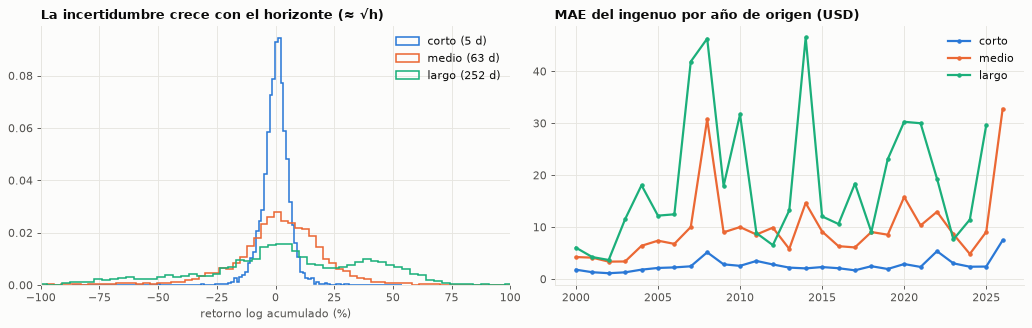

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for name, y in dists.items():
    axes[0].hist(y * 100, bins=120, density=True, histtype="step", lw=1.4, label=f"{name} ({HORIZONS[name]} d)")
axes[0].set_xlim(-100, 100); axes[0].legend(); axes[0].set_xlabel("retorno log acumulado (%)")
axes[0].set_title("La incertidumbre crece con el horizonte (≈ √h)")
mae_year = pd.DataFrame({n: (price.shift(-h) - price).abs().groupby(price.index.year).mean() for n, h in HORIZONS.items()})
mae_year.plot(ax=axes[1], marker="o", ms=3); axes[1].set_title("MAE del ingenuo por año de origen (USD)"); axes[1].set_xlabel("")
plt.tight_layout()

- A 5 días el precio se mueve típicamente ±6 %; a 63 días ±22 %; a 252 días ±37 %. Un intervalo del 80 % honesto a un año será **amplio**: hay que comunicarlo como valor ("sabemos cuánto no sabemos").
- El error del ingenuo se dispara en 2008, 2014-15, 2020, 2022 y 2026. **El test (2024-2026) es especialmente exigente.**

## Resumen para el feature engineering y el modelado

| Hallazgo | Consecuencia |
|---|---|
| Precio no estacionario, retorno sí | Objetivo = retorno log acumulado a *h* días |
| Retornos sin memoria | El ingenuo es el listón real; esperar mejoras pequeñas |
| Volatilidad con memoria | Variables de volatilidad; intervalos que se adaptan a la volatilidad |
| Colas pesadas | Winsorización de entradas por fold |
| Sin estacionalidad | Sin variables de calendario |
| WTI de ayer anticipa al Brent de hoy | Retorno diario del futuro WTI como entrada |
| Relaciones inestables (oferta vs demanda) | Validación por años; explicar el riesgo de cambio de régimen en la app |